# The summed window integral and height with the tail line fit and the wider window (-82 V, DCRC1pB trigger)

*Draft prepared with Claude Code for A. Villano, 2026-11-03.*

This notebook is `window-integral-small-quiet-82v.ipynb` applied to the reprocessing **`r76-82V-window-integral-tail.dataset.toml`**. That definition differs from `r76-82V-window-integral` in two places:

* **`subtract_line` fits its line to the post-trigger tail**, samples 2375 to 4095 (from 1.5 ms after the trigger to the end), instead of to the whole trace. The fit therefore leaves the pulse out. The line is carried back under the pulse, and every quantity is then measured from the mean of samples 10 to 450 of what is left;
* **`window_integral` runs over samples 400 to 1500**, from -100 to +1000 samples around the trigger at sample 500 (-80 to +800 us), instead of 450 to 950.

**The cuts are the same** as in `window-integral-small-quiet-82v.ipynb`, computed from the quantities of `r76-82v-dcrc1pb.dataset.toml`:

* real triggers, with the series `07221113_1159` left out;
* `bstd` below twice the random triggers' median in all six channels;
* six 20 % times within 60 us of their median;
* **no cut on the size** (`SIZE_CUT = False`).

**The blob** is the tight circle of 4 us around (22, 2) us. **The comparison** is the events outside the old 10 us circle.

Both datasets hold the same 436 dumps in the same order, and the first cell checks this. The integrals and heights are summed over the six channels. A section compares them with those of `r76-82V-window-integral`, and the last section is a GIF of tight-blob pulses drawn as this processing sees them. Run with the `darkmatter_cli_env` kernel.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyarrow.compute as pc
import pyarrow.parquet as pq
from matplotlib import colors

from goldpan.dataset import Dataset

LETTERS = "ABCDEF"
_here = Path.cwd().resolve()
PROCESSING = next(p / "data_analysis" / "R76" / "processing" for p in [_here, *_here.parents] if (p / "data_analysis" / "R76" / "processing").is_dir())
OUT_CUTS = Path(Dataset.open(PROCESSING / "r76-82v-dcrc1pb.dataset.toml").spec.output)          # the cuts, as in positions-small-quiet-82v
OUT_WIN = Path(Dataset.open(PROCESSING / "r76-82V-window-integral-tail.dataset.toml").spec.output)   # the window integral and the heights
PRE = json.loads((OUT_CUTS / "_goldpan.json").read_text(encoding="utf-8"))["streams"]["NAI-S2"]["detector"]["segments"][0]["pretrigger_samples"]
CACHE = Path.home() / "goldsluice-output" / f"relcal-positions-small-82v-p{PRE}.npz"             # the cache of positions-small-quiet-82v
WCACHE = Path.home() / "goldsluice-output" / "relcal-window-integral-tail-82v.npz"               # this notebook's: the window integral and the row check
WCACHE_OLD = Path.home() / "goldsluice-output" / "relcal-window-integral-82v.npz"               # that of window-integral-small-quiet-82v (r76-82V-window-integral)

def field(tab, k, name):
    # one quantity of one channel: the channel is a struct column of the Parquet file
    return pc.struct_field(tab[f"Side2p{k}"].combine_chunks(), name).to_numpy(zero_copy_only=False)

def files(out):
    return sorted((out / "NAI-S2").glob("*_F[0-9][0-9][0-9][0-9].parquet"))

if CACHE.exists():
    z = np.load(CACHE)
    series, trigger, bstd, height, t = z["series"], z["trigger"], z["bstd"], z["height"], z["t"]
else:
    S_, T_, B_, H_, X_ = [], [], [], [], []
    for f in files(OUT_CUTS):
        tab = pq.read_table(f, columns=["series", "trigger_type"] + [f"Side2p{k}" for k in LETTERS])
        S_.append(np.asarray(tab["series"].to_pylist())); T_.append(np.asarray(tab["trigger_type"].to_pylist()))
        B_.append(np.column_stack([field(tab, k, "baseline_std") for k in LETTERS]))
        H_.append(np.column_stack([field(tab, k, "current_max") for k in LETTERS]))
        X_.append(np.column_stack([field(tab, k, "crossing_time_s") for k in LETTERS]) * 1e6)       # microseconds
    series, trigger, bstd, height, t = np.concatenate(S_), np.concatenate(T_), np.vstack(B_), np.vstack(H_), np.vstack(X_)
    np.savez(CACHE, series=series, trigger=trigger, bstd=bstd, height=height, t=t)

def keys(out, window=False):
    # series/dump/event of every row, and (window=True) the window integral of the six channels
    K, X = [], []
    for f in files(out):
        tab = pq.read_table(f, columns=["series", "dump", "event"] + ([f"Side2p{k}" for k in LETTERS] if window else []))
        K.append(np.array([f"{s}/{d}/{e}" for s, d, e in zip(tab["series"].to_pylist(), tab["dump"].to_pylist(), tab["event"].to_pylist())]))
        if window:
            X.append(np.column_stack([field(tab, k, "window_integral") for k in LETTERS]))
    return np.concatenate(K), (np.vstack(X) if window else None)

if WCACHE.exists():
    z = np.load(WCACHE)
    wint, same_rows = z["wint"], bool(z["same_rows"])
else:
    k_cuts, _ = keys(OUT_CUTS)
    k_win, wint = keys(OUT_WIN, window=True)
    same_rows = len(k_cuts) == len(k_win) and bool((k_cuts == k_win).all())
    np.savez(WCACHE, wint=wint, same_rows=same_rows)
assert same_rows and len(wint) == len(series), "the two datasets do not hold the same events in the same order"
real, rand = trigger == "Unknown", trigger == "Physics"
print(f"{len(series):,} events in {len(np.unique(series))} series, the same rows in both datasets: {real.sum():,} real triggers")

1,466,349 events in 8 series, the same rows in both datasets: 1,436,655 real triggers


## The cuts

The same cut flow as `positions-small-quiet-82v.ipynb`, with the same numbers, plus the blob.

In [2]:
SATH = np.array([1277, 1095, 589, 930, 680, 883.0])         # saturated height of each channel (saturation-over-time.ipynb)
FRAC = 0.05
BSTD_CUT = np.array([2 * np.median(bstd[rand, i]) for i in range(6)])
WINDOW = 60.0                                               # microseconds: the six times of one pulse lie within this of their median
OFFSET_X, OFFSET_Y = 0.5, 12.0                              # the re-centred plane of positions-small-quiet-82v
BLOB_X, BLOB_Y = 22.0, 2.0                                  # us, in that plane: the densest point of the small events
BLOB_R = 4.0        # us: the tight blob. The density of the small events is 53, 48, 46, 43 per us^2 in 1 us rings out to 4 us, and halves by about 7 us
BLOB_R_OUT = 10.0   # us: the old blob circle (the density falls to a quarter); the comparison set is outside it
EXCLUDE = {"07221113_1159"}
SIZE_CUT = False                                            # True: no channel above FRAC of its saturation (positions-small-quiet-82v)

keep = ~np.isin(series, list(EXCLUDE))
bstd_ok = (bstd < BSTD_CUT).all(axis=1)
small = (height < FRAC * SATH).all(axis=1)
size_ok = small if SIZE_CUT else np.ones(len(series), bool)
finite = np.isfinite(t).all(axis=1)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    one_pulse = (np.abs(t - np.nanmedian(t, axis=1, keepdims=True)) < WINDOW).all(axis=1)
xdel = t[:, 4] - 0.5 * (t[:, 2] + t[:, 3]) + OFFSET_X
ydel = 0.866 * (t[:, 3] - t[:, 2]) + OFFSET_Y
steps = [("real triggers", real & keep), ("+ bstd below the cut in all six channels", real & keep & bstd_ok),
         ("+ no channel above 5 % of its saturation" if SIZE_CUT else "  (no cut on the size)", real & keep & bstd_ok & size_ok),
         ("+ six 20 % times", real & keep & bstd_ok & size_ok & finite),
         ("+ one pulse (times within 60 us)", real & keep & bstd_ok & size_ok & finite & one_pulse)]
for name, m in steps:
    print(f"{name:<46}{m.sum():>11,}")
use = steps[-1][1]
r_blob = np.hypot(xdel - BLOB_X, ydel - BLOB_Y)
blob, rest = use & (r_blob < BLOB_R), use & (r_blob >= BLOB_R_OUT)
randoms = rand & keep
print(f"{'   in the blob':<46}{blob.sum():>11,}")
print(f"{'   between 4 and 10 us (in neither set)':<46}{(use & (r_blob >= BLOB_R) & (r_blob < BLOB_R_OUT)).sum():>11,}")
print(f"{'   outside the blob (beyond 10 us)':<46}{rest.sum():>11,}")
print(f"{'random triggers (for the zero)':<46}{randoms.sum():>11,}")

wsum = wint.sum(axis=1)                                     # all six channels, ADC counts x s
for name, m in (("selected", use), ("blob", blob), ("outside the blob", rest), ("random triggers", randoms)):
    p = np.percentile(wsum[m], [10, 50, 90])
    print(f"{name:>18}: summed window integral 10/50/90 %: " + "  ".join(f"{v:8.5f}" for v in p))

real triggers                                   1,292,982
+ bstd below the cut in all six channels        1,088,121
  (no cut on the size)                          1,088,121
+ six 20 % times                                1,053,964
+ one pulse (times within 60 us)                1,031,670
   in the blob                                      8,861
   between 4 and 10 us (in neither set)            95,769
   outside the blob (beyond 10 us)                927,040
random triggers (for the zero)                     25,511
          selected: summed window integral 10/50/90 %:  0.40083   2.42478   3.92647
              blob: summed window integral 10/50/90 %:  0.01787   0.04465   0.42861


  outside the blob: summed window integral 10/50/90 %:  0.64987   2.60056   3.96936
   random triggers: summed window integral 10/50/90 %: -0.19189  -0.00250   0.08418


### The blob in the plane

The plane of the delays (re-centred, `x` reversed as in `positions-small-quiet-82v.ipynb`) for the small events (all six channels below 5 % of saturation, the other cuts as above) and for the selected events of every size, with the tight blob (white) and the old 10 us circle (dashed).

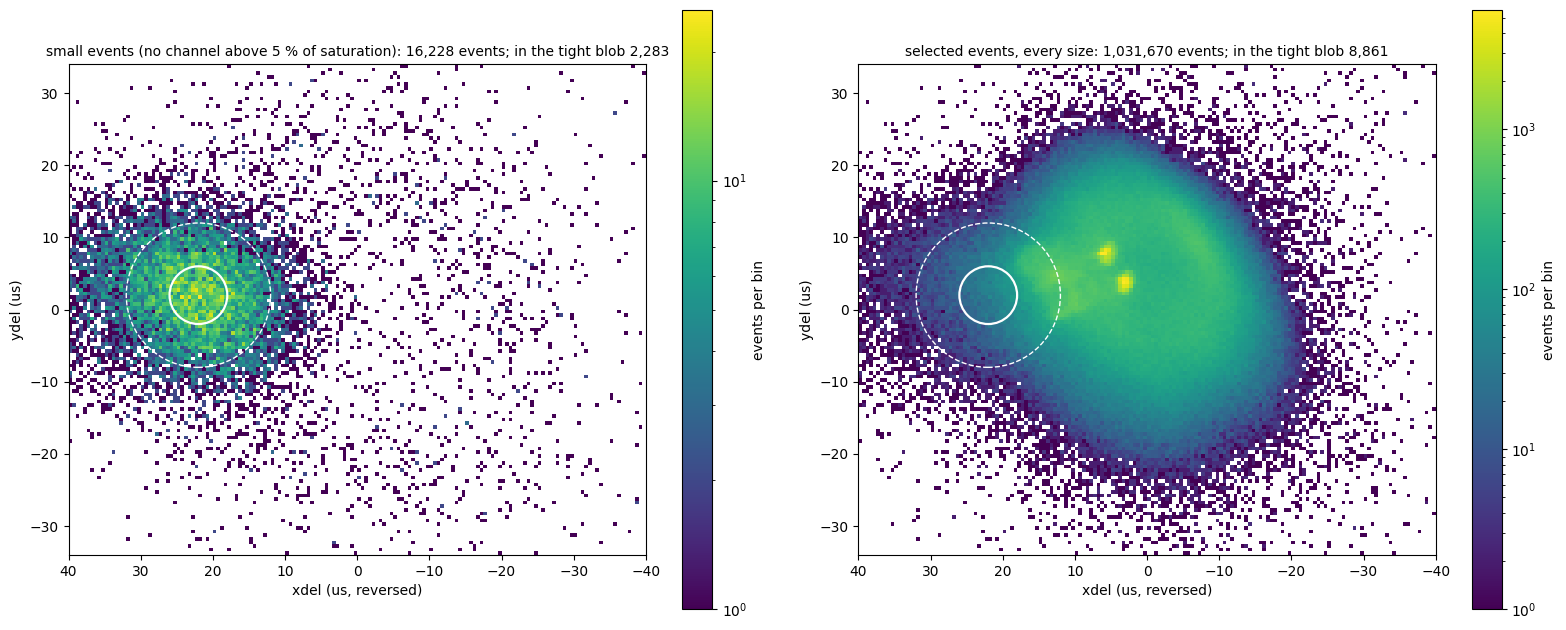

In [3]:
from matplotlib.patches import Circle
small_sel = use & small
fig, axes = plt.subplots(1, 2, figsize=(16, 6.4))
for ax, m, title in ((axes[0], small_sel, "small events (no channel above 5 % of saturation)"), (axes[1], use, "selected events, every size")):
    h = ax.hist2d(xdel[m], ydel[m], bins=[160, 136], range=[[-40, 40], [-34, 34]], cmap="viridis", norm=colors.LogNorm(), cmin=1)
    fig.colorbar(h[3], ax=ax, label="events per bin")
    ax.add_patch(Circle((BLOB_X, BLOB_Y), BLOB_R, fill=False, ec="w", lw=1.6))
    ax.add_patch(Circle((BLOB_X, BLOB_Y), BLOB_R_OUT, fill=False, ec="w", lw=1.0, ls="--"))
    ax.set_xlim(40, -40); ax.set_ylim(-34, 34); ax.set_aspect("equal")
    ax.set_xlabel("xdel (us, reversed)"); ax.set_ylabel("ydel (us)")
    ax.set_title(f"{title}: {m.sum():,} events; in the tight blob {(m & (r_blob < BLOB_R)).sum():,}", fontsize=10)
fig.tight_layout()
plt.show()

## The summed window integral

The window integral summed over the six channels, A to F, for the blob, for the other small, quiet events, and for the random triggers. The random triggers show where zero is and how wide the noise is. Counts per bin on a log vertical scale: the low end (the small pulses and the zero of the random triggers) and the full range.

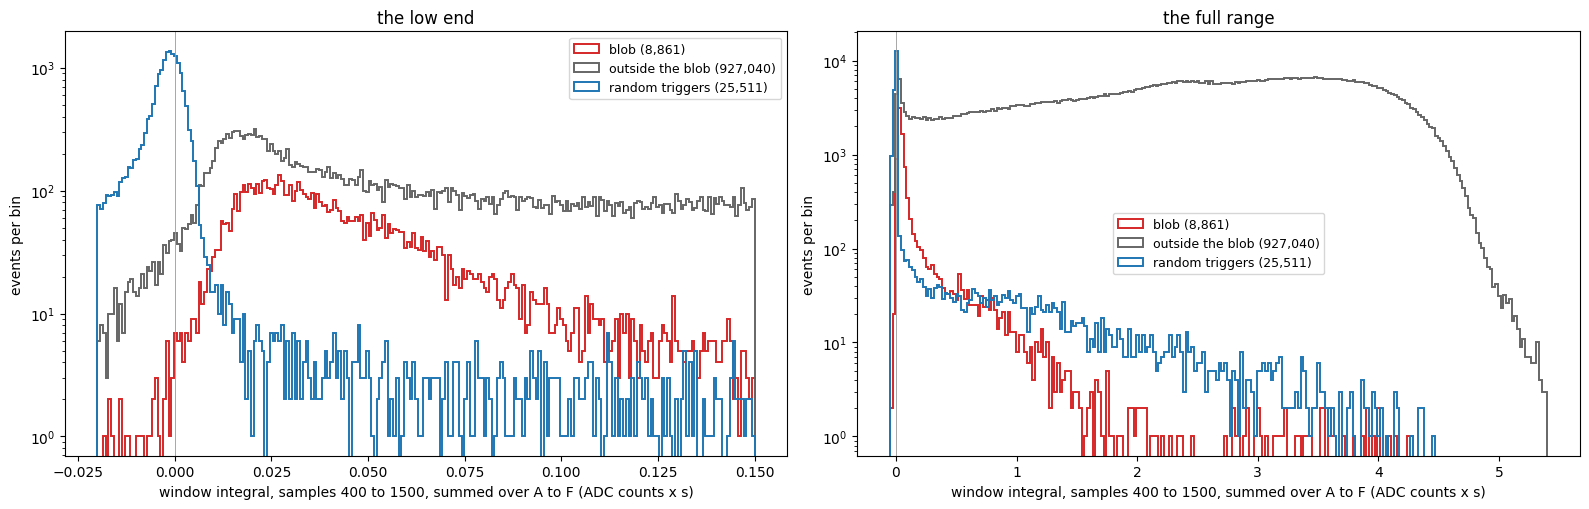

In [4]:
SETS = ((blob, "C3", f"blob ({blob.sum():,})"), (rest, "0.4", f"outside the blob ({rest.sum():,})"),
        (randoms, "C0", f"random triggers ({randoms.sum():,})"))
WMAX = 1.05 * np.percentile(wsum[use], 99.99)             # the full range of the summed window integral
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for ax, bins, zoom in ((axes[0], np.linspace(-0.02, 0.15, 241), True), (axes[1], np.linspace(-0.05, WMAX, 241), False)):
    for m, c, lab in SETS:
        ax.hist(wsum[m], bins=bins, histtype="step", color=c, linewidth=1.4, label=lab)
    ax.axvline(0, color="0.6", linewidth=0.6)
    ax.set_xlabel("window integral, samples 400 to 1500, summed over A to F (ADC counts x s)")
    ax.set_ylabel("events per bin")
    ax.set_yscale("log")
    ax.set_title("the low end" if zoom else "the full range")
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

### Against `r76-82V-window-integral` (whole-trace line, samples 450 to 950)

The summed window integral of this processing against that of `r76-82V-window-integral`, for the same events, from the cache of `window-integral-small-quiet-82v.ipynb` (`relcal-window-integral-82v.npz`; that notebook makes it if it is missing). On the left the spectra of the tight blob, old and new. On the right, the new against the old, event by event, for the blob and for the events outside the 10 us circle. The ratio new / old is given for a few ranges of the old value.

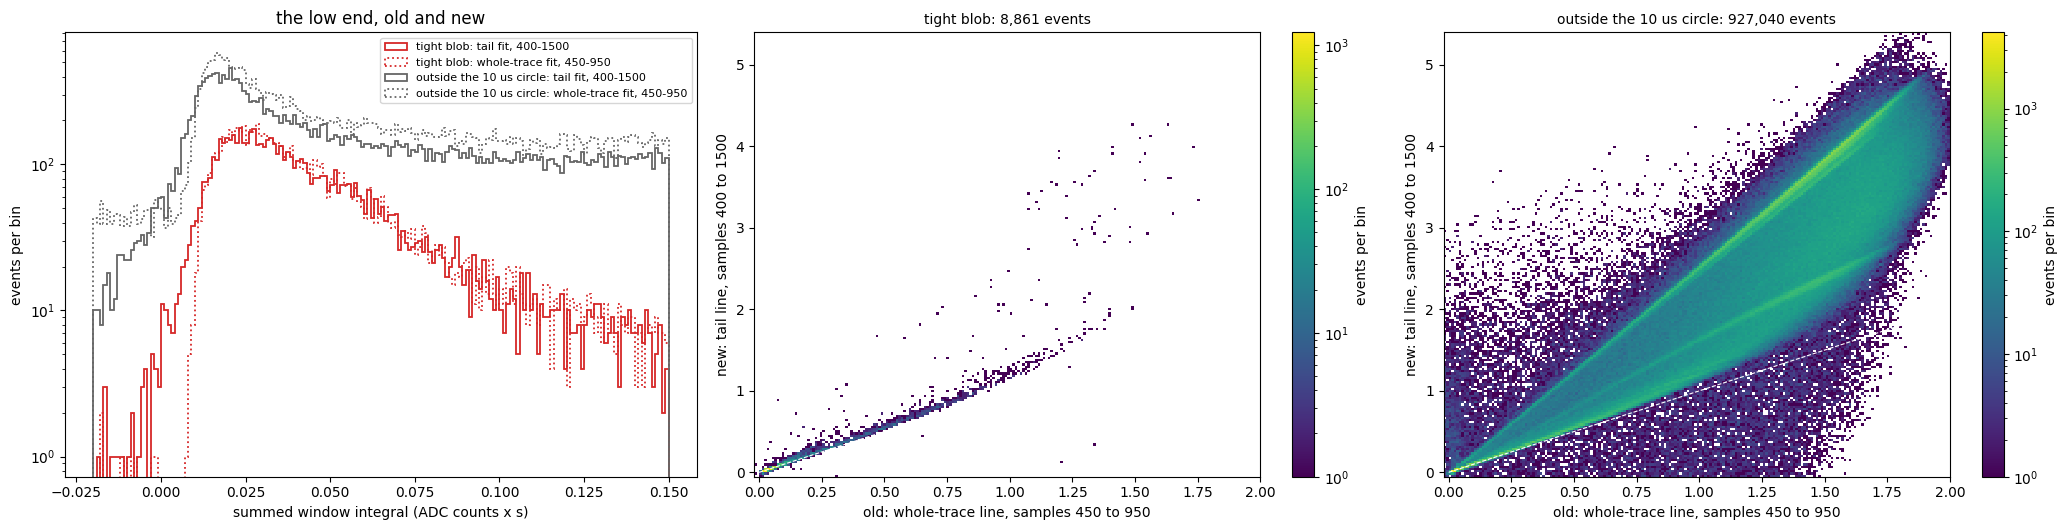

               tight blob, old sum 0.005 to 0.050:    4,903 events, new / old 10/50/90 %: 0.749  1.003  1.127
               tight blob, old sum 0.050 to 0.300:    2,907 events, new / old 10/50/90 %: 0.956  1.047  1.239
               tight blob, old sum 0.300 to 1.000:      906 events, new / old 10/50/90 %: 1.070  1.124  1.264
               tight blob, old sum 1.000 to 2.500:      136 events, new / old 10/50/90 %: 1.170  1.323  2.767
 outside the 10 us circle, old sum 0.005 to 0.050:   14,014 events, new / old 10/50/90 %: 0.483  1.007  2.061
 outside the 10 us circle, old sum 0.050 to 0.300:   37,839 events, new / old 10/50/90 %: 0.993  1.102  2.387
 outside the 10 us circle, old sum 0.300 to 1.000:  188,835 events, new / old 10/50/90 %: 1.095  1.531  2.489
 outside the 10 us circle, old sum 1.000 to 2.500:  678,683 events, new / old 10/50/90 %: 1.485  2.110  2.549


In [5]:
wsum_old = np.load(WCACHE_OLD)["wint"].sum(axis=1)
assert len(wsum_old) == len(wsum)
fig, axes = plt.subplots(1, 3, figsize=(21, 5.4))
for m, c, lab in ((blob, "C3", "tight blob"), (rest, "0.4", "outside the 10 us circle")):
    for q, ls, which in ((wsum, "-", "tail fit, 400-1500"), (wsum_old, ":", "whole-trace fit, 450-950")):
        axes[0].hist(q[m], bins=np.linspace(-0.02, 0.15, 171), histtype="step", color=c, ls=ls, lw=1.3, label=f"{lab}: {which}")
axes[0].set_yscale("log"); axes[0].set_xlabel("summed window integral (ADC counts x s)"); axes[0].set_ylabel("events per bin")
axes[0].set_title("the low end, old and new"); axes[0].legend(fontsize=8)
for ax, (m, title) in zip(axes[1:], ((blob, "tight blob"), (rest, "outside the 10 us circle"))):
    h = ax.hist2d(wsum_old[m], wsum[m], bins=[200, 200], range=[(-0.02, 2.0), (-0.01 * WMAX, WMAX)], cmap="viridis", norm=colors.LogNorm(), cmin=1)
    fig.colorbar(h[3], ax=ax, label="events per bin")
    ax.plot([0, 2], [0, 2], color="w", lw=0.8, ls="--")
    ax.set_xlabel("old: whole-trace line, samples 450 to 950"); ax.set_ylabel("new: tail line, samples 400 to 1500")
    ax.set_title(f"{title}: {m.sum():,} events", fontsize=10)
fig.tight_layout()
plt.show()
for name, m in (("tight blob", blob), ("outside the 10 us circle", rest)):
    for lo, hi in ((0.005, 0.05), (0.05, 0.3), (0.3, 1.0), (1.0, 2.5)):
        k = m & (wsum_old >= lo) & (wsum_old < hi)
        if k.sum() > 20:
            print(f"{name:>25}, old sum {lo:5.3f} to {hi:5.3f}: {k.sum():>8,} events, new / old 10/50/90 %: "
                  + "  ".join(f"{v:.3f}" for v in np.percentile(wsum[k] / wsum_old[k], [10, 50, 90])))

### All six channels against the inner four, and against Side2pF

The sum over the inner channels, C + D + E + F, and the Side2pF window integral, each plotted against the sum over all six. One pulse shape, shared the same way among the channels, would put the events on one line through the origin.

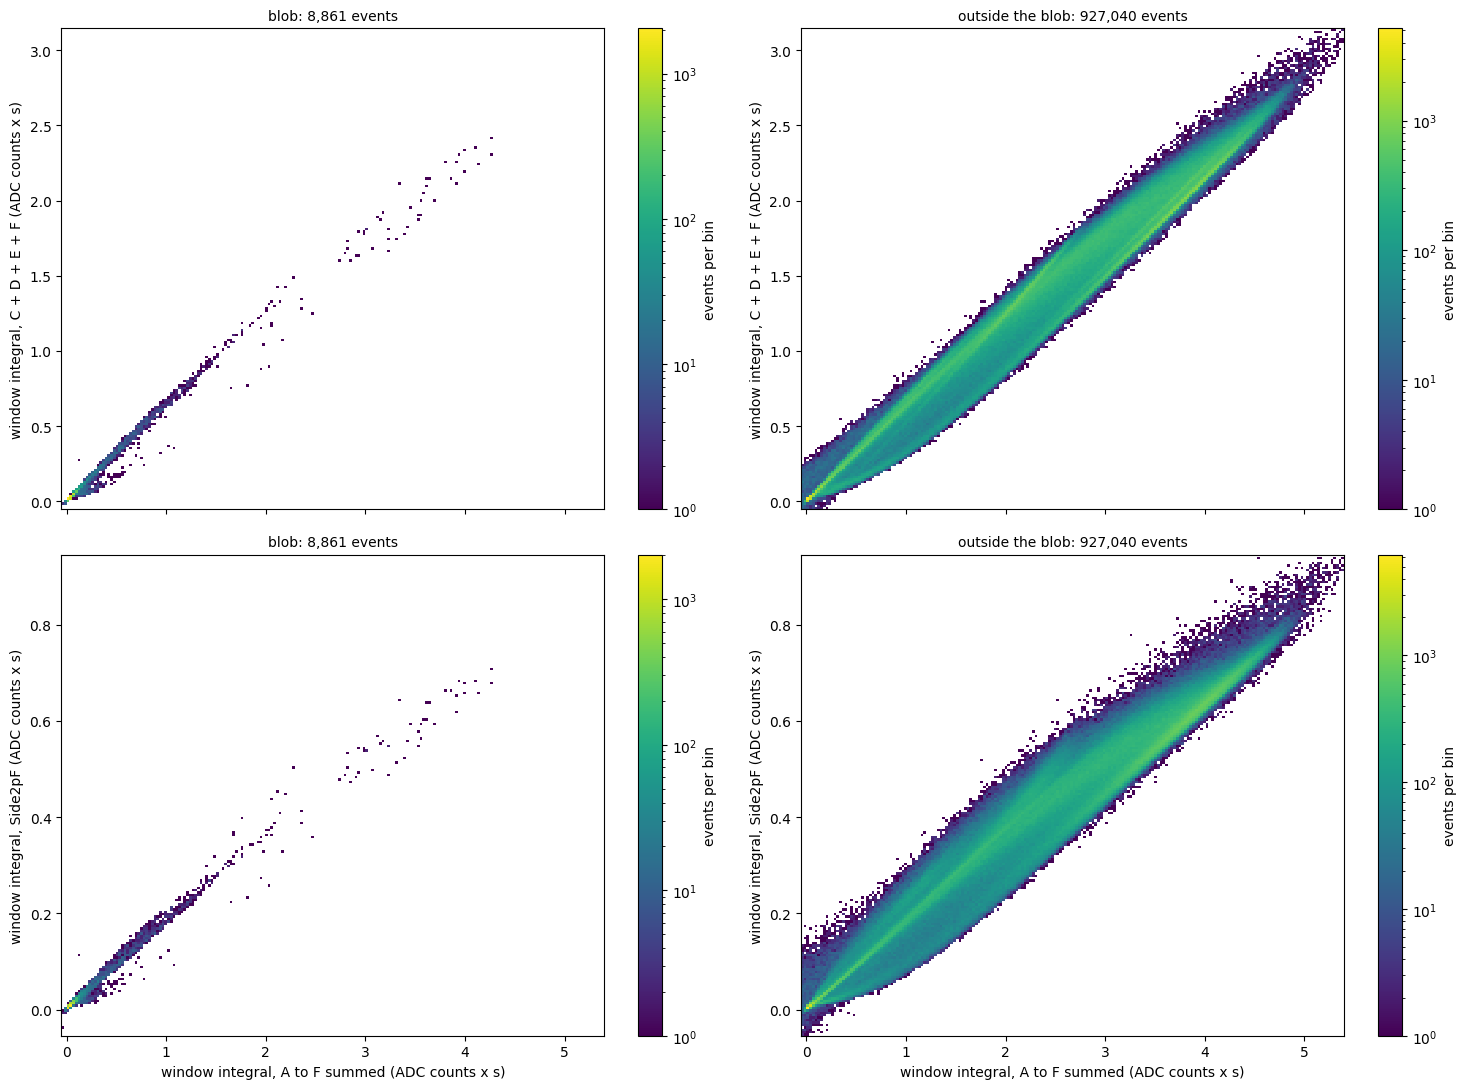

In [6]:
inner = wint[:, 2:].sum(axis=1)
fig, axes = plt.subplots(2, 2, figsize=(15, 11), sharex=True)
for col, (m, title) in enumerate(((blob, "blob"), (rest, "outside the blob"))):
    for row, (y, ylab) in enumerate(((inner, "C + D + E + F"), (wint[:, 5], "Side2pF"))):
        ax = axes[row, col]
        yr = (-0.01 * WMAX, 1.05 * np.percentile(y[use], 99.99))
        h = ax.hist2d(wsum[m], y[m], bins=[200, 200], range=[(-0.01 * WMAX, WMAX), yr], cmap="viridis", norm=colors.LogNorm(), cmin=1)
        fig.colorbar(h[3], ax=ax, label="events per bin")
        ax.set_ylabel(f"window integral, {ylab} (ADC counts x s)")
        ax.set_title(f"{title}: {m.sum():,} events", fontsize=10)
for ax in axes[1]:
    ax.set_xlabel("window integral, A to F summed (ADC counts x s)")
fig.tight_layout()
plt.show()

### All the events, with the bstd cut only

The summed window integral of every real trigger that passes the `bstd` cut in all six channels, with the selected events drawn on the same axis: the difference between the two is what the cut on the times removes. The window ends 800 us after the trigger, while the large pulses last more than a millisecond, so for those events it still covers only part of the pulse.

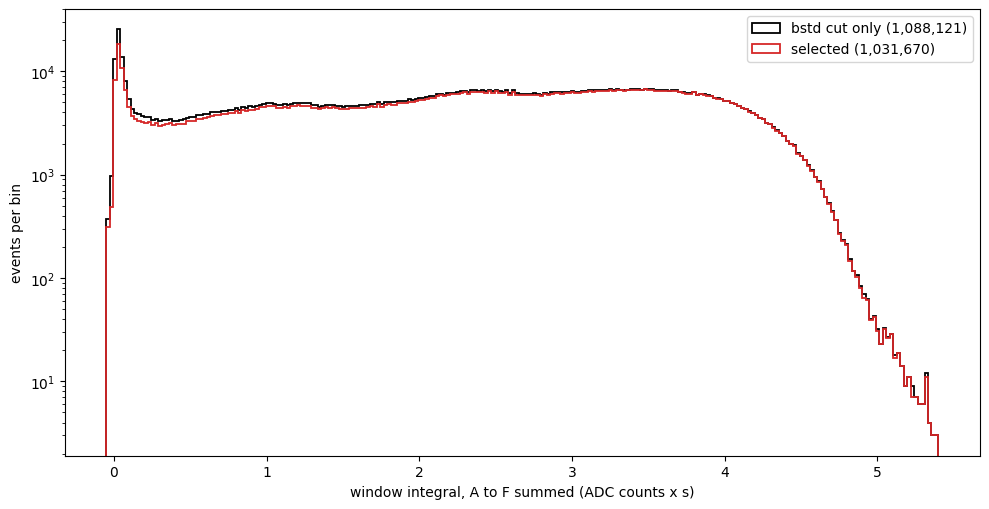

In [7]:
BINS_ALL = np.linspace(-0.05, WMAX, 241)
fig, ax = plt.subplots(figsize=(10, 5.2))
for m, c, lab in ((real & keep & bstd_ok, "k", f"bstd cut only ({(real & keep & bstd_ok).sum():,})"), (use, "C3", f"selected ({use.sum():,})")):
    ax.hist(wsum[m], bins=BINS_ALL, histtype="step", color=c, linewidth=1.3, label=lab)
ax.set_yscale("log")
ax.set_xlabel("window integral, A to F summed (ADC counts x s)")
ax.set_ylabel("events per bin")
ax.legend()
fig.tight_layout()
plt.show()

## The summed maximum height

The same cuts again, now with the pulse height: `current_max`, the largest value of the trace above its baseline, summed over the six channels. The heights come from `r76-82V-window-integral-tail`, so they are taken from the same traces the window integral uses: the tail line subtracted, and measured from the pretrigger mean. They are read once and cached next to the window integral (`relcal-height-tail-82v.npz`).

The cut on the size, no channel above 5 % of saturation, uses the heights of the old dataset. **A maximum is never zero:** on a trace with no pulse it picks the largest upward noise excursion. The random triggers therefore sit at a positive height, a few counts per channel, and their sum is not centred on zero, unlike the integral.

          selected: summed height 10/50/90 %:  1516.4   4067.2   5415.4 counts
              blob: summed height 10/50/90 %:   138.7    275.5   1749.8 counts
  outside the blob: summed height 10/50/90 %:  1992.3   4190.7   5477.8 counts
   random triggers: summed height 10/50/90 %:    40.6     59.2   2276.0 counts
random triggers, per channel, median height: A 7.4, B 11.9, C 6.5, D 11.1, E 6.4, F 6.6


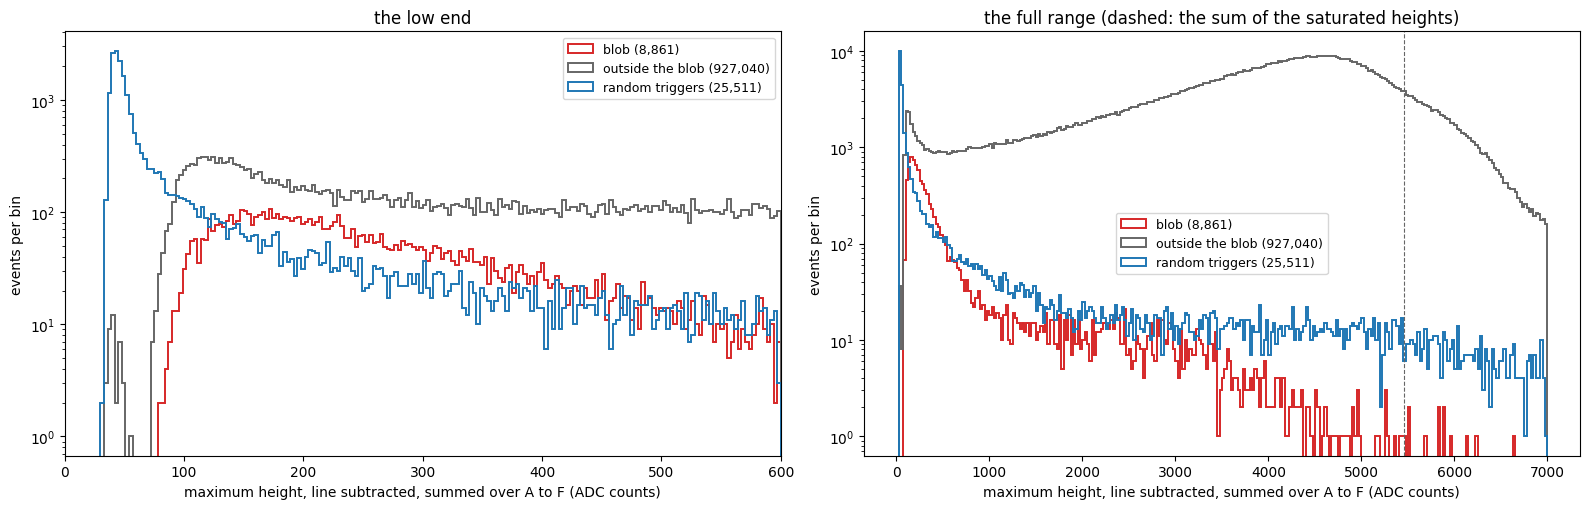

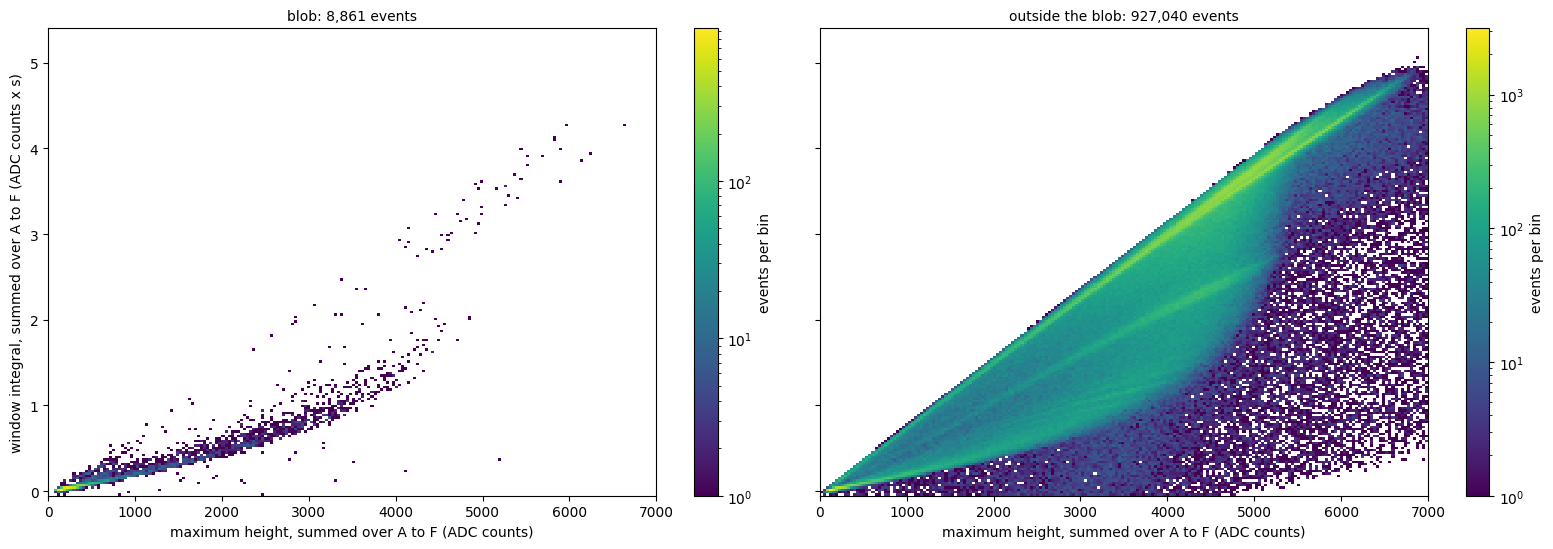

In [8]:
HCACHE = Path.home() / "goldsluice-output" / "relcal-height-tail-82v.npz"
if HCACHE.exists():
    hwin = np.load(HCACHE)["hwin"]
else:
    hwin = np.vstack([np.column_stack([field(pq.read_table(f, columns=[f"Side2p{k}" for k in LETTERS]), k, "current_max") for k in LETTERS])
                      for f in files(OUT_WIN)])
    np.savez(HCACHE, hwin=hwin)
assert len(hwin) == len(series), "the height cache does not match: delete it and rerun"
hsum = hwin.sum(axis=1)                                     # ADC counts, all six channels
for name, m in (("selected", use), ("blob", blob), ("outside the blob", rest), ("random triggers", randoms)):
    p = np.percentile(hsum[m], [10, 50, 90])
    print(f"{name:>18}: summed height 10/50/90 %: " + "  ".join(f"{v:7.1f}" for v in p) + " counts")
print("random triggers, per channel, median height: " + ", ".join(f"{k} {v:.1f}" for k, v in zip(LETTERS, np.median(hwin[randoms], axis=0))))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2))
for ax, bins, zoom in ((axes[0], np.arange(0, 601, 3), True), (axes[1], np.arange(0, 7001, 25), False)):
    for m, c, lab in SETS:
        ax.hist(hsum[m], bins=bins, histtype="step", color=c, linewidth=1.4, label=lab)
    ax.axvline(SATH.sum(), color="0.4", ls="--", lw=0.8)
    ax.set_xlabel("maximum height, line subtracted, summed over A to F (ADC counts)")
    ax.set_ylabel("events per bin")
    ax.set_yscale("log")
    if zoom:
        ax.set_xlim(0, 600)
    ax.set_title("the low end" if zoom else "the full range (dashed: the sum of the saturated heights)")
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

# the summed height against the summed window integral
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), sharex=True, sharey=True)
for ax, (m, title) in zip(axes, ((blob, "blob"), (rest, "outside the blob"))):
    h = ax.hist2d(hsum[m], wsum[m], bins=[200, 200], range=[(0, 7000), (-0.01 * WMAX, WMAX)], cmap="viridis", norm=colors.LogNorm(), cmin=1)
    fig.colorbar(h[3], ax=ax, label="events per bin")
    ax.set_xlabel("maximum height, summed over A to F (ADC counts)")
    ax.set_title(f"{title}: {m.sum():,} events", fontsize=10)
axes[0].set_ylabel("window integral, summed over A to F (ADC counts x s)")
fig.tight_layout()
plt.show()

### All the events, with the bstd cut only

The summed height of every real trigger that passes the `bstd` cut in all six channels, with the selected events and the random triggers on the same axis. The sum of the saturated heights is 5,454 counts, marked by the dashed line.

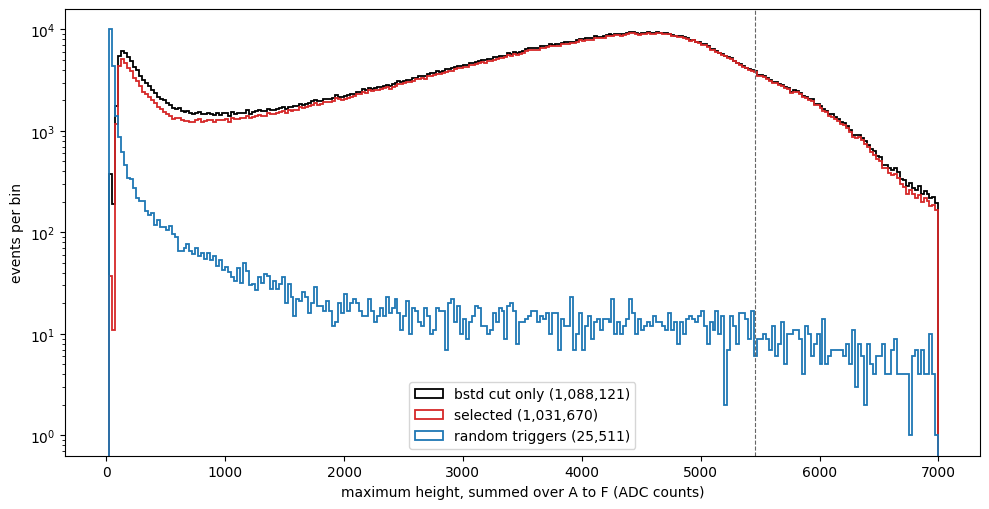

In [9]:
BINS_HA = np.arange(0, 7001, 25)
fig, ax = plt.subplots(figsize=(10, 5.2))
for m, c, lab in ((real & keep & bstd_ok, "k", f"bstd cut only ({(real & keep & bstd_ok).sum():,})"), (use, "C3", f"selected ({use.sum():,})"),
                  (randoms, "C0", f"random triggers ({randoms.sum():,})")):
    ax.hist(hsum[m], bins=BINS_HA, histtype="step", color=c, linewidth=1.3, label=lab)
ax.axvline(SATH.sum(), color="0.4", ls="--", lw=0.8)
ax.set_yscale("log")
ax.set_xlabel("maximum height, summed over A to F (ADC counts)")
ax.set_ylabel("events per bin")
ax.legend()
fig.tight_layout()
plt.show()

## The traces of the tight blob, as a GIF

One frame per event of the tight blob, with the six channels tiled. Each trace is drawn as the window integral of this processing sees it. First the straight line fitted to the tail, samples 2375 to 4095, is subtracted (`subtract_line` with `glitch_samples = 2375`, `fit_end_samples = 4096`; the tail is shaded green). Then the mean of samples 10 to 450 of what is left is subtracted, as `window_integral` does. The dashed line at zero is that baseline, and the integral is the area above it inside the window (orange, samples 400 to 1500). The dotted line is the fitted line itself, carried back under the pulse. The window of `window_integral`, samples 450 to 950, is shaded, and every panel gives that channel's window integral from the dataset. The title gives the sum over the six channels.

**The sample** is 48 events, ordered by their summed window integral. Most of them are taken from the low end, since that is where the blob is:
* 36 events with a sum between 0.005 and 0.15, spaced evenly in rank, so they follow the distribution;
* 12 events above 0.15, also spaced evenly in rank.

The sample is drawn with the summed window integral of this processing. The traces are read once from the raw dumps in `~/idx` and cached (`relcal-tight-blob-traces-tail.npz`). The first cell also checks that the window integral recomputed from them matches the dataset's. The GIF is saved as `figures/tight-blob-traces-tail.gif`.

In [10]:
from goldpan.adapters import idx
from goldpan.config import PulseConfig
import goldpan.channels as pch
from matplotlib.animation import PillowWriter

WIN = (400, 1500)                                           # the window of r76-82V-window-integral-tail.dataset.toml
FIT = (2375, 4096)                                          # subtract_line: glitch_samples to fit_end_samples (the tail)
N_LOW, N_HIGH, LOW_MAX = 36, 12, 0.15
TCACHE = Path.home() / "goldsluice-output" / "relcal-tight-blob-traces-tail.npz"

def spaced(idx_, n):
    # n events of idx_ spaced evenly in rank of the summed window integral
    idx_ = idx_[np.argsort(wsum[idx_])]
    return idx_[np.unique(np.linspace(0, len(idx_) - 1, n).round().astype(int))]

cand = np.flatnonzero(blob)
pick = np.r_[spaced(cand[(wsum[cand] > 0.005) & (wsum[cand] <= LOW_MAX)], N_LOW), spaced(cand[wsum[cand] > LOW_MAX], N_HIGH)]
pick = pick[np.argsort(wsum[pick])]

if TCACHE.exists() and np.array_equal(np.load(TCACHE)["pick"], pick):
    z = np.load(TCACHE)
    traces, labels = z["traces"], z["labels"]
else:
    k_all, _ = keys(OUT_WIN)
    labels = k_all[pick]
    cfg = PulseConfig(pretrigger_samples=PRE, glitch_samples=10, sample_period_s=0.8e-6)
    SENSORS = {c.name: (c.detector, c.channel) for c in pch.sensor_channels()}
    traces = np.full((len(pick), 6, 4096), np.nan)
    by_dump = {}
    for n, lab in enumerate(labels):
        s, d, e = lab.split("/")
        by_dump.setdefault((s, d), []).append((n, int(e)))
    for (s, d), items in sorted(by_dump.items()):
        ev = idx.read(Path.home() / "idx" / (d if d.startswith(s) else f"{s}_{d}"), detector_name="NAI-S2", channels=SENSORS, config=cfg)
        row = {int(e): j for j, e in enumerate(np.asarray(ev.quantities["event"]))}
        segment = {nm: seg for (nm, seg) in ev.traces}
        for n, e in items:
            for c, k in enumerate(LETTERS):
                traces[n, c] = np.asarray(ev.traces[(f"Side2p{k}", segment[f"Side2p{k}"])], dtype=float)[row[e]]
    np.savez(TCACHE, pick=pick, traces=traces, labels=labels)

s_fit = np.arange(*FIT)
slope, icpt = np.polyfit(s_fit, traces.reshape(-1, 4096)[:, s_fit].T, 1)
flat = (traces.reshape(-1, 4096) - (slope[:, None] * np.arange(4096) + icpt[:, None])).reshape(traces.shape)
line_at = -flat[:, :, 10:PRE].mean(axis=2, keepdims=True)  # where the fitted line lies, measured from the baseline of window_integral
flat = flat + line_at                                      # the trace minus its line, minus the pretrigger mean of what is left
mine = flat[:, :, WIN[0]:WIN[1]].sum(axis=2) * 0.8e-6
print(f"{len(pick)} events from {len(set(l.rsplit('/', 1)[0] for l in labels))} dumps; summed window integral from {wsum[pick].min():.4f} to {wsum[pick].max():.4f}")
print(f"window integral recomputed against the dataset's: largest difference {np.abs(mine - wint[pick]).max():.2e} ADC counts x s")

C:\Users\Anthony\AppData\Local\Temp\ipykernel_27036\3377291519.py:27: UserWarning: sensor_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  SENSORS = {c.name: (c.detector, c.channel) for c in pch.sensor_channels()}


48 events from 44 dumps; summed window integral from 0.0051 to 4.2727
window integral recomputed against the dataset's: largest difference 1.00e-15 ADC counts x s


figures\tight-blob-traces-tail.gif: 48 frames, one per second


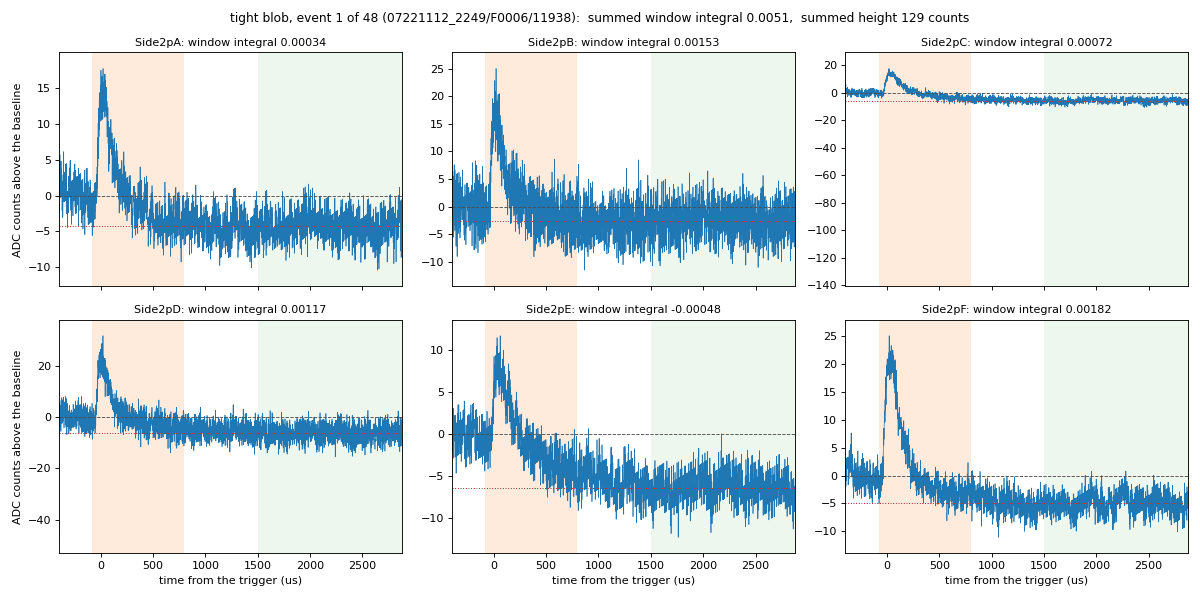

In [11]:
from IPython.display import Image, display

t_us = (np.arange(4096) - 500) * 0.8                         # microseconds from the trigger
GIF = Path("figures") / "tight-blob-traces-tail.gif"
GIF.parent.mkdir(exist_ok=True)
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)
writer = PillowWriter(fps=1)
with writer.saving(fig, GIF, dpi=80):
    for n in range(len(pick)):
        for c, ax in enumerate(axes.flat):
            ax.clear()
            ax.axvspan(t_us[WIN[0]], t_us[WIN[1] - 1], color="C1", alpha=0.15, lw=0)
            ax.axvspan(t_us[FIT[0]], t_us[FIT[1] - 1], color="C2", alpha=0.08, lw=0)
            ax.plot(t_us, flat[n, c], color="C0", lw=0.6)
            ax.axhline(0, color="0.3", ls="--", lw=0.8)
            ax.axhline(line_at[n, c, 0], color="C3", ls=":", lw=0.9)
            ax.set_xlim(t_us[0], t_us[-1])
            pad = 0.08 * (flat[n, c].max() - flat[n, c].min())
            ax.set_ylim(flat[n, c].min() - pad, flat[n, c].max() + pad)
            ax.set_title(f"Side2p{LETTERS[c]}: window integral {wint[pick[n], c]:.5f}", fontsize=10)
            if c >= 3:
                ax.set_xlabel("time from the trigger (us)")
            if c % 3 == 0:
                ax.set_ylabel("ADC counts above the baseline")
        fig.suptitle(f"tight blob, event {n + 1} of {len(pick)} ({labels[n]}):  summed window integral {wsum[pick[n]]:.4f},  "
                     f"summed height {hsum[pick[n]]:.0f} counts", fontsize=11)
        fig.tight_layout()
        writer.grab_frame()
plt.close(fig)
print(f"{GIF}: {len(pick)} frames, one per second")
display(Image(filename=str(GIF)))